In [3]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from wordcloud import WordCloud
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report, confusion_matrix
import nltk

nltk.download('punkt', quiet = True)
nltk.download('stopwords', quiet = True)
nltk.download('wordnet', quiet = True)

df = pd.read_csv('dataset/Tweets.csv')
df.head(5)

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [4]:
########## PART - A #################
def clean_text(text):
    text = re.sub(r'http\S+|www\S+|https\S+', '', str(text), flags=re.MULTILINE) 
    text = re.sub(r'@\w+', '', text) 
    text = re.sub(r'#\w+', '', text) 
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'[^\w\s]', '', text)
    return text.lower()

df['cleaned_text'] = df['text'].apply(clean_text)

stop_words = set(stopwords.words('english'))
negations = {'not', 'no', 'nor', 'didn', 'doesn', 'isn', 'wasn', 'aren', 'couldn', 'won', 'wouldn'}
custom_stopwords = stop_words - negations

def remove_stopwords(text):
    tokens = word_tokenize(text)
    return ' '.join([word for word in tokens if word not in custom_stopwords])

df['no_stopwords'] = df['cleaned_text'].apply(remove_stopwords)

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

df['stemmed'] = df['no_stopwords'].apply(lambda x: ' '.join([stemmer.stem(w) for w in word_tokenize(x)]))
df['lemmatized'] = df['no_stopwords'].apply(lambda x: ' '.join([lemmatizer.lemmatize(w) for w in word_tokenize(x)]))
df['raw_length'] = df['text'].apply(lambda x: len(str(x).split()))
df['clean_length'] = df['lemmatized'].apply(lambda x: len(str(x).split()))
print(f"Tweets left completely empty = {len(df[df['clean_length'] == 0])}")
print(f"Average words removed per tweet = {(df['raw_length'] - df['clean_length']).mean():.2f}")

Tweets left completely empty = 20
Average words removed per tweet = 8.42


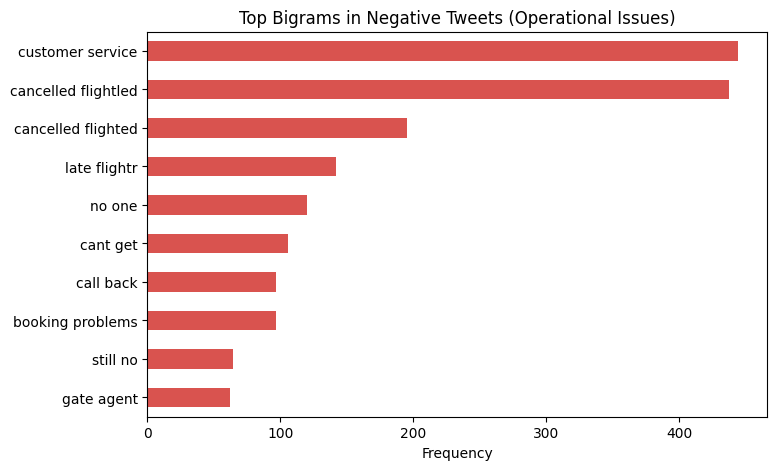

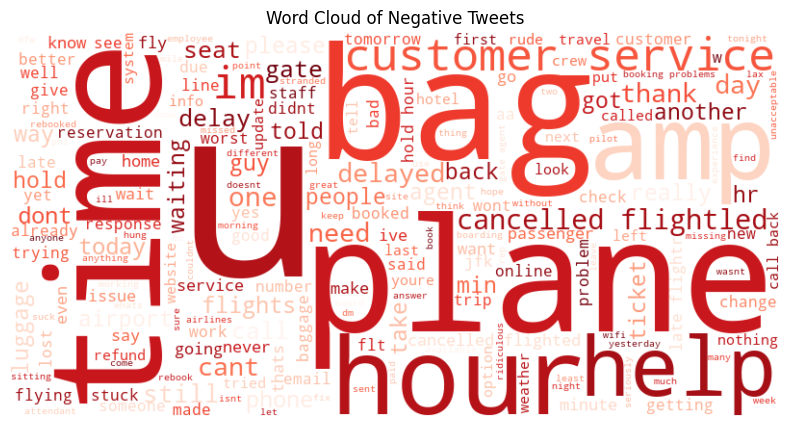

In [5]:
########## PART - B #################
airline_names = {'united', 'usairways', 'americanair', 'southwestair', 'jetblue', 'virginamerica', 'flight', 'airline'}
final_stopwords = custom_stopwords.union(airline_names)

df['final_text'] = df['cleaned_text'].apply(lambda x: ' '.join([w for w in word_tokenize(x) if w not in final_stopwords]))

tfidf = TfidfVectorizer(max_features=15)
neg_docs = df[df['airline_sentiment'] == 'negative']['final_text']

tfidf_neg = tfidf.fit_transform(neg_docs)
neg_scores = pd.DataFrame(tfidf_neg.sum(axis=0).T, index=tfidf.get_feature_names_out(), columns=['TF-IDF']).sort_values('TF-IDF', ascending=False)

vectorizer = CountVectorizer(ngram_range=(2, 2), max_features=10)
X_bigrams = vectorizer.fit_transform(neg_docs)
bigram_counts = pd.DataFrame(X_bigrams.sum(axis=0).T, index=vectorizer.get_feature_names_out(), columns=['Count']).sort_values('Count', ascending=True)
bigram_counts.plot(kind='barh', figsize=(8, 5), color='#d9534f', legend=False)
plt.title('Top Bigrams in Negative Tweets (Operational Issues)')
plt.xlabel('Frequency')
plt.show()

text_for_cloud = ' '.join(neg_docs)
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(text_for_cloud)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Negative Tweets')
plt.show()

Overall Model vs Human Agreement:
              precision    recall  f1-score   support

    negative       0.90      0.44      0.59      9178
     neutral       0.39      0.32      0.35      3099
    positive       0.28      0.91      0.43      2363

    accuracy                           0.49     14640
   macro avg       0.52      0.56      0.46     14640
weighted avg       0.69      0.49      0.51     14640



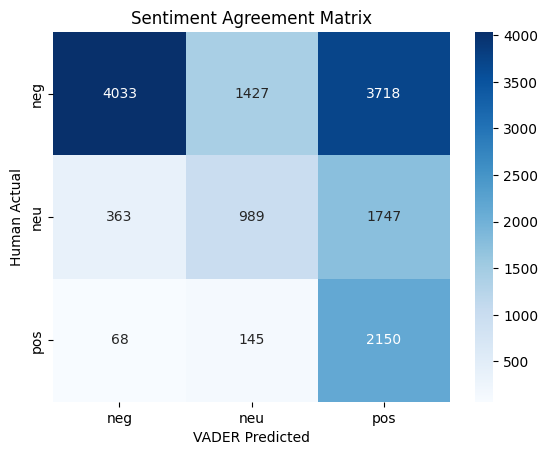


Agreement on High Confidence Labels Only:
              precision    recall  f1-score   support

    negative       0.95      0.48      0.64      7392
     neutral       0.34      0.37      0.35      1550
    positive       0.29      0.94      0.44      1517

    accuracy                           0.53     10459
   macro avg       0.52      0.60      0.48     10459
weighted avg       0.76      0.53      0.57     10459



In [6]:
########## PART - C #################
analyzer = SentimentIntensityAnalyzer()

def get_vader_sentiment(text):
    score = analyzer.polarity_scores(text)['compound']
    if score >= 0.05: return 'positive'
    elif score <= -0.05: return 'negative'
    else: return 'neutral'

df['vader_pred'] = df['text'].apply(get_vader_sentiment)

print("Overall Model vs Human Agreement:")
print(classification_report(df['airline_sentiment'], df['vader_pred']))

sns.heatmap(confusion_matrix(df['airline_sentiment'], df['vader_pred'], labels=['negative', 'neutral', 'positive']), annot=True, fmt='d', cmap='Blues', xticklabels=['neg', 'neu', 'pos'], yticklabels=['neg', 'neu', 'pos'])
plt.xlabel('VADER Predicted')
plt.ylabel('Human Actual')
plt.title('Sentiment Agreement Matrix')
plt.show()

high_conf_df = df[df['airline_sentiment_confidence'] >= 0.8]
print("\nAgreement on High Confidence Labels Only:")
print(classification_report(high_conf_df['airline_sentiment'], high_conf_df['vader_pred']))

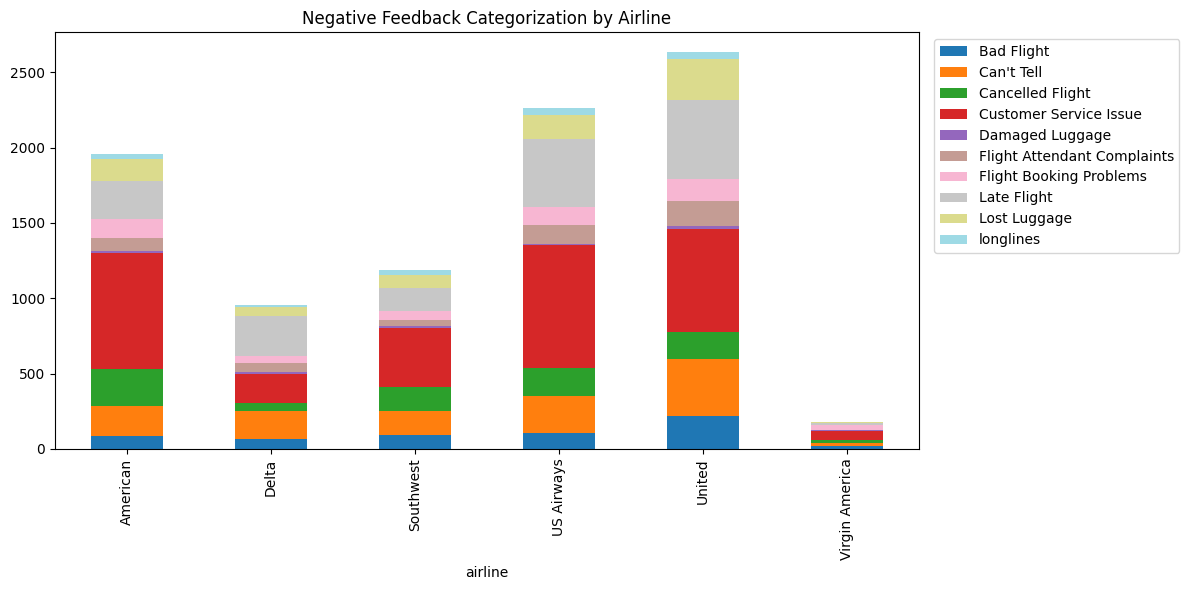

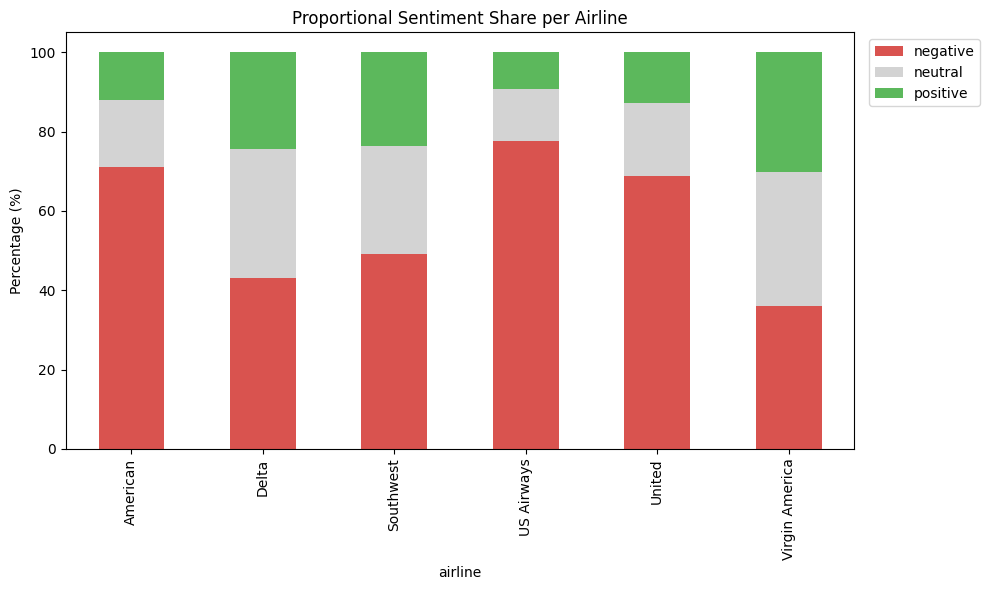

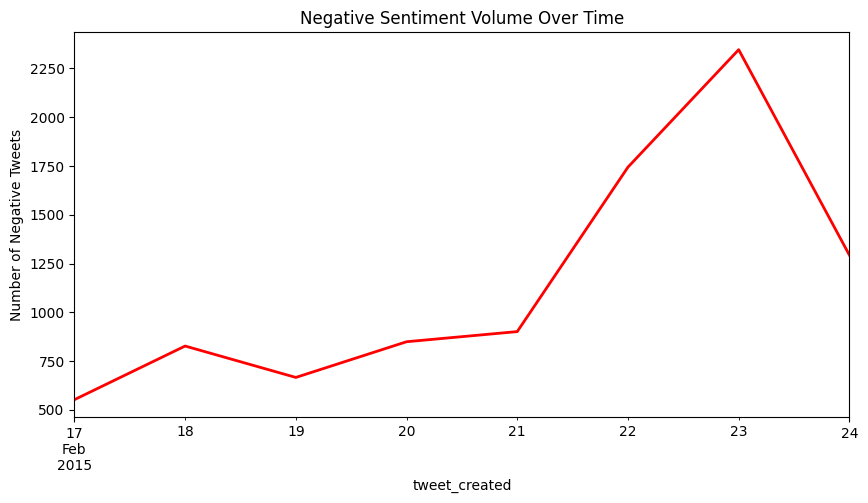

In [7]:
########## PART - D #################
complaints = df[df['airline_sentiment'] == 'negative']
reason_counts = complaints.groupby(['airline', 'negativereason']).size().unstack().fillna(0)
reason_counts.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab20')
plt.title('Negative Feedback Categorization by Airline')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

sentiment_by_airline = df.groupby(['airline', 'airline_sentiment']).size().unstack()
sentiment_pct = sentiment_by_airline.div(sentiment_by_airline.sum(axis=1), axis=0) * 100

sentiment_pct[['negative', 'neutral', 'positive']].plot(kind='bar', stacked=True, figsize=(10, 6), color=['#d9534f', '#d3d3d3', '#5cb85c'])
plt.title('Proportional Sentiment Share per Airline')
plt.ylabel('Percentage (%)')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

df['tweet_created'] = pd.to_datetime(df['tweet_created'], utc=True)
time_series = df.set_index('tweet_created').groupby(pd.Grouper(freq='D'))['airline_sentiment'].value_counts().unstack().fillna(0)
time_series['negative'].plot(figsize=(10, 5), color='red', linewidth=2)
plt.title('Negative Sentiment Volume Over Time')
plt.ylabel('Number of Negative Tweets')
plt.show()

## Part E: Critical Evaluation

**1. Twitter Bias & Misleading the Airline**
Twitter users are not a random sample of passengers. This dataset could mislead the airline in three ways:
* **Selection Bias (The Extremes):** People usually only tweet at a brand when they are very angry or extremely happy. The "silent majority" of passengers who had a fine, uneventful flight are not represented.
* **Demographic Bias:** Twitter users skew younger and more tech-savvy. The complaints of elderly passengers or non-digital natives are completely missed.
* **Platform Intent:** Many tweets are performative or seeking compensation rather than offering genuine feedback. 
* *Least Trusted Finding:* The overall ratio of positive to negative sentiment. It looks overwhelmingly negative, but this likely reflects Twitter's complaint-heavy nature, not the actual reality of all daily flights.

**2. 2015 Data vs. Today**
Because this data is from 2015, several findings would likely change today:
* **Wi-Fi & Tech:** Complaints about "slow wifi" or "no charging ports" would likely decrease, as in-flight tech has improved significantly since 2015.
* **New Operational Issues:** Data today would likely feature new n-grams related to modern post-COVID travel, staffing shortages, or app-related boarding issues.
* **Bot Activity:** The sheer volume of spam or bot accounts on X (formerly Twitter) today would require much heavier preprocessing than in 2015.

**3. Replacing the Manual Team (Recommendation)**
*Recommendation:* **Do not fully replace** the manual reading team with the automated tool; instead, move to a **hybrid triage system**.
*Reasoning:* As seen in Part C, lexicon-based tools like VADER fail on domain-specific negative terms (e.g., "flight delayed 3 hours" contains no inherently negative words but is a terrible experience) and sarcasm ("Great, another delay"). The AI should be used to instantly route and flag high-priority tweets (triage), but human agents are still required to understand context, empathy, and sarcasm before replying.

Insight 1 - Average Tweet Length (Characters):
airline_sentiment
negative    113.947919
neutral      87.359471
positive     86.082945
Name: tweet_len, dtype: float64


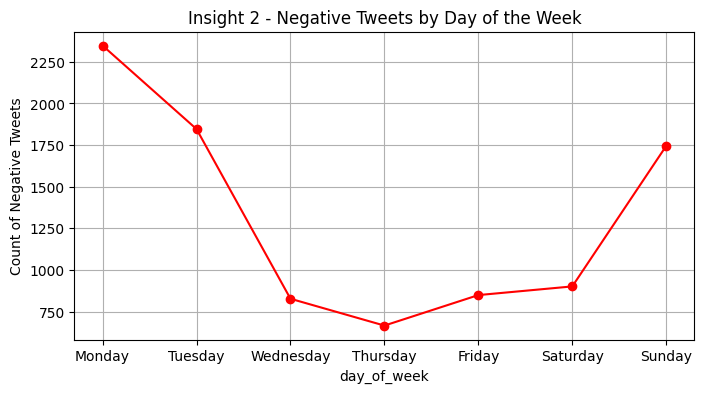

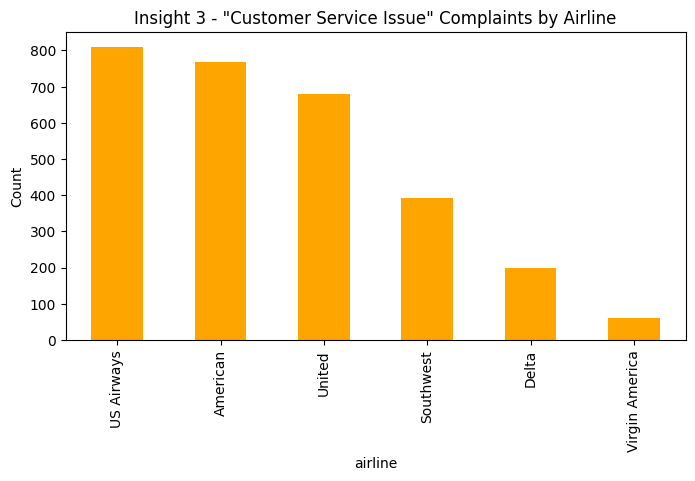

In [8]:
########## PART - F #################
df['tweet_len'] = df['text'].apply(len)
length_by_sent = df.groupby('airline_sentiment')['tweet_len'].mean()
print("Insight 1 - Average Tweet Length (Characters):")
print(length_by_sent)

df['tweet_created'] = pd.to_datetime(df['tweet_created'], utc=True)
df['day_of_week'] = df['tweet_created'].dt.day_name()
cats = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['day_of_week'] = pd.Categorical(df['day_of_week'], categories=cats, ordered=True)

daily_complaints = df[df['airline_sentiment'] == 'negative']['day_of_week'].value_counts().sort_index()
daily_complaints.plot(kind='line', marker='o', figsize=(8, 4), color='red')
plt.title('Insight 2 - Negative Tweets by Day of the Week')
plt.ylabel('Count of Negative Tweets')
plt.grid(True)
plt.show()

neg_reasons = df[df['airline_sentiment']=='negative'].groupby(['airline', 'negativereason']).size().unstack()
cs_issues = neg_reasons['Customer Service Issue'].sort_values(ascending=False)
cs_issues.plot(kind='bar', color='orange', figsize=(8, 4))
plt.title('Insight 3 - "Customer Service Issue" Complaints by Airline')
plt.ylabel('Count')
plt.show()

## Part F: Additional Insights

### Insight 1: Angry Customers Write More
* **Observation:** Negative tweets are significantly longer on average (~ 114 characters) compared to neutral (~ 87 characters) or positive tweets (~ 86 characters).
* **Evidence:** The `tweet_len` group-by calculation shows a nearly 30-character jump for negative sentiment.
* **Why it matters:** Customers aren't just dropping quick negative emojis; they are taking the time to write out detailed, specific paragraphs about their bad experiences.
* **Recommended action:** Set up a routing rule that prioritizes longer negative tweets (over 100 characters) for senior customer service reps, as these likely contain complex, multi-layered grievances.
* **Confidence and limits:** High confidence in the character count, but limited by Twitter's 140-character limit (in 2015). We don't know if they would have written even more if allowed.

### Insight 2: The Monday/Tuesday Complaint Spike
* **Observation:** Negative tweets spike massively on Sundays, Mondays, and Tuesdays, and drop significantly on Thursdays and Fridays.
* **Evidence:** The line chart showing the count of negative tweets by day of the week peaks on Monday (over 2,300 tweets) and hits a low on Thursday (~ 660 tweets).
* **Why it matters:** Customer service teams are likely facing overwhelming backlogs at the start of the week (possibly due to weekend travel delays overflowing into Monday).
* **Recommended action:** Shift staff scheduling to ensure maximum customer service agents are on shift from Sunday evening through Tuesday afternoon. 
* **Confidence and limits:** Moderate confidence. The data is only from February 2015. We would need a full year of data to ensure this isn't just a result of a specific weekend snowstorm.

### Insight 3: The American/US Airways Customer Service Crisis
* **Observation:** US Airways and American Airlines have a drastically higher volume of specific "Customer Service Issue" complaints compared to major competitors like Delta.
* **Evidence:** The bar chart shows US Airways (>800) and American (>750) dwarf Delta (~ 199) in this specific category.
* **Why it matters:** While weather and late flights happen to everyone, "Customer Service Issue" is a controllable, human-driven metric. This points to a systemic training or cultural issue at those two specific airlines.
* **Recommended action:** The Director should investigate the agent training programs at Delta and adapt them for US Airways and American Airlines.
* **Confidence and limits:** High confidence in the raw numbers, but limited by missing context (e.g., we don't know the total number of flights each airline operated during this period to create a per-capita rate).